# Analiza dividendnih delnic

V tej analizi bom preučil **1.000 delnic z najvišjim dividendnim donosom**, pridobljenih s [Finviz screenerjem](https://finviz.com/screener.ashx) (podatki zajeti oktobra 2026).

Izbral sem podjetja, ki **izplačujejo dividendo** in imajo **tržno kapitalizacijo nad 2 milijardama USD**, ter jih razvrstil **od največjega dividendnega donosa do najmanjšega**.

S tem zagotovimo, da se osredotočamo na **priznana, stabilna podjetja**, kjer je izplačilo dividend bolj zanesljivo in reprezentativno.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
delnice = pd.read_csv("PODATKI/delnice.csv")



In [2]:
delnice.head()
#preverimo če dela

,oznaka,podjetje,sektor,panoga,drzava,trzna_kapitalizacija,dividenda,donos,obseg,cena
0,IEP,Icahn Enterprises L P,Energy,Oil & Gas Refining & Marketing,USA,4.750000e+09,2.00,29.96,217950.0,6.68
1,CLM,Cornerstone Strategic Investment Fund Inc,Financial,Closed-End Fund - Equity,USA,2.000000e+09,1.46,22.63,715190.0,6.47
2,DX,Dynex Capital Inc,Real Estate,REIT - Mortgage,USA,2.690000e+09,2.04,18.81,2046056.0,10.85
3,ECO,Okeanis Eco Tankers Corp,Industrials,Marine Shipping,Greece,3.360000e+09,16.44,18.74,277634.0,87.74
4,PDI,PIMCO Dynamic Income Fund,Financial,Closed-End Fund - Debt,USA,6.840000e+09,2.64,18.40,2243217.0,14.35


## 1) Pregled podatkov

In [3]:
delnice.describe()


,trzna_kapitalizacija,dividenda,donos,obseg,cena
count,1.000000e+03,1000.000000,1000.00000,1.000000e+03,1000.000000
mean,3.782630e+10,2.411130,3.61518,7.951238e+05,92.191990
std,7.665097e+10,2.520422,2.81584,2.149243e+06,108.453767
min,2.000000e+09,0.060000,0.92000,1.895000e+03,1.680000
25%,4.587500e+09,0.977500,1.86750,9.499625e+04,28.920000
50%,1.051500e+10,1.775000,2.88000,2.434500e+05,58.725000
75%,3.438750e+10,3.040000,4.50000,6.640255e+05,113.590000
max,8.814500e+11,32.690000,29.96000,3.428117e+07,1078.330000



Z ukazom `describe()` sem izračunal osnovno statistiko za vse številske stolpce: povprečje (`mean`), standardni odklon (`std`), najmanjšo in največjo vrednost ter kvartile (`25%`, `50%` – mediana, `75%`).
Številke so zapisane v znanstvenem zapisu npr. `3.78e+10` pomeni 37,8 milijarde USD

**Dividendni donos** se giblje med **0,92 %** in **29,96 %**. Povprečni donos je **3,62 %**, mediana pa **2,88 %**. Ker je povprečni donos opazno višji od mediane, lahko sklepamo, da ima večina delnic zmeren donos, peščica delnic z izjemno visokim donosom pa povprečje potegne navzgor. Tri četrtine delnic ima donos pod 4,5 %.

**Cena** delnic je zelo raznolika: najcenejša stane **1,68 USD**, najdražja pa kar **1.078 USD**. Mediana je **58,73 USD**, povprečje pa **92,19 USD**, kar spet kaže na nekaj zelo dragih delnic, ki dvignejo povprečje.

**Tržna kapitalizacija** najmanjša podjetja imajo po filtru točno 2 milijardi USD, največje pa kar **881 milijard USD**. Polovica podjetij je vredna manj kot 10,5 milijarde USD.

**Obseg trgovanja** se med delnicami zelo razlikuje: od manj kot 2.000 do več kot 34 milijonov delnic v enem dnevu.

## 2) Kakšni so dividendni donosi?

Najprej si poglejmo, kako so donosi porazdeljeni med vsemi 1.000 delnicami.

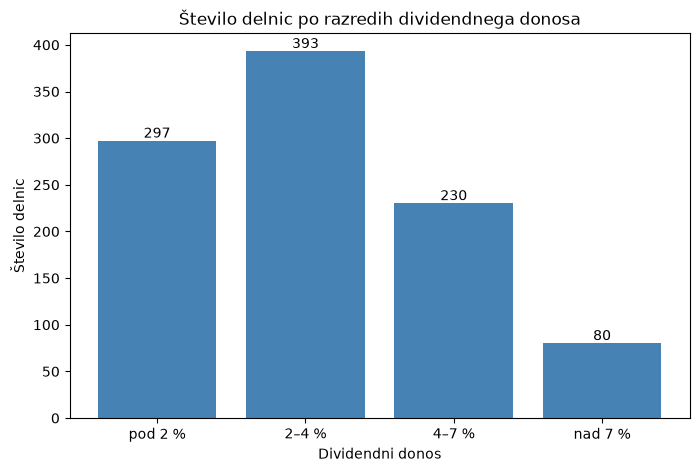

In [4]:
#donose razdelimo na intervale
razredi = pd.cut(
    delnice["donos"],
    bins=[0, 2, 4, 7, 100],
    labels=["pod 2 %", "2–4 %", "4–7 %", "nad 7 %"]
)
stevila = razredi.value_counts().sort_index()

plt.figure(figsize=(8, 5))
stolpci = plt.bar(stevila.index.astype(str), stevila.values, color="steelblue")
plt.bar_label(stolpci)
plt.title("Število delnic po razredih dividendnega donosa")
plt.xlabel("Dividendni donos")
plt.ylabel("Število delnic")
plt.show()

Največ delnic , ima donos med **2 in 4 %**, sledijo delnice z donosom **pod 2 %** (**297**) in med **4 in 7 %** (**230**). Donos **nad 7 %** ima le **80**. Nepričakovanih odstopanja nisem opazil.



## 3) Sektorji

Poglejmo, iz katerih sektorjev prihajajo delnice in kateri sektorji imajo v povprečju najvišji dividendni donos.

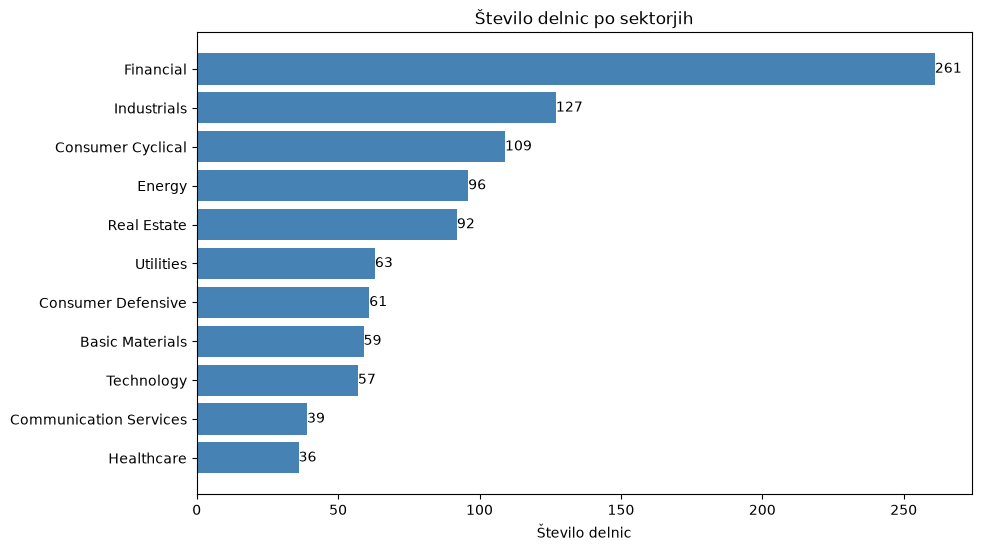

In [5]:
st_po_sektorjih = delnice["sektor"].value_counts()

plt.figure(figsize=(10, 6))
stolpci = plt.barh(st_po_sektorjih.index, st_po_sektorjih.values, color="steelblue")
plt.bar_label(stolpci)
plt.gca().invert_yaxis()
plt.title("Število delnic po sektorjih")
plt.xlabel("Število delnic")
plt.show()

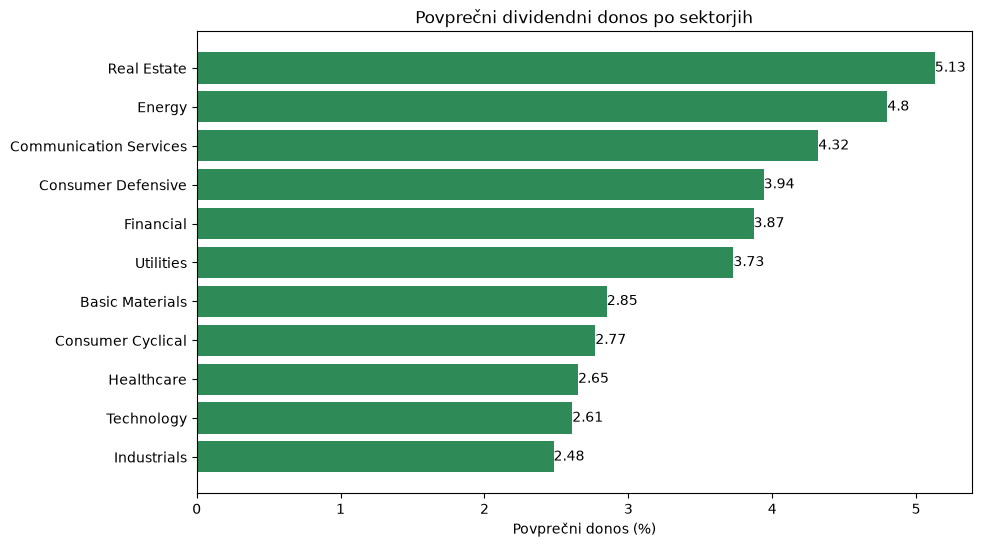

In [6]:
donos_po_sektorjih = delnice.groupby("sektor")["donos"].mean().sort_values(ascending=False).round(2)

plt.figure(figsize=(10, 6))
stolpci = plt.barh(donos_po_sektorjih.index, donos_po_sektorjih.values, color="seagreen")
plt.bar_label(stolpci)
plt.gca().invert_yaxis()
plt.title("Povprečni dividendni donos po sektorjih")
plt.xlabel("Povprečni donos (%)")
plt.show()

Daleč največ delnic, kar **261** (več kot četrtina), prihaja iz **finančnega sektorja** (Financial), sledita **industrija** (Industrials, 127) in **ciklične potrošne dobrine** (Consumer Cyclical, 109). Najmanj je delnic iz **zdravstva** (Healthcare, 36) in **komunikacij** (Communication Services, 39).

Pri povprečnem donosu je slika precej drugačna. Najvišji povprečni donos imajo **nepremičnine** (Real Estate, **5,13 %**) in **energetika** (Energy, **4,80 %**). Nepremičninska podjetja (REIT) morajo po zakonu večino dobička izplačati delničarjem, energetska podjetja pa imajo pogosto visoke denarne tokove. Najnižji donos imajo **industrija** (**2,48 %**), **tehnologija** (**2,61 %**) in **zdravstvo** (**2,65 %**), ki dobiček raje vlagajo v rast.

Zanimivo je, da finančni sektor, ki ima največ delnic, s povprečnim donosom **3,87 %** pristane šele na sredini. Sektor z največ dividendnimi podjetji torej ni nujno tudi sektor z najvišjimi dividendami.

## 4) Države

Poglejmo, iz katerih držav prihajajo podjetja.

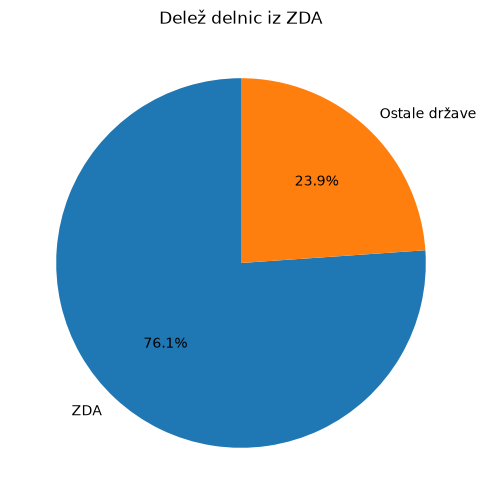

In [7]:
st_zda = (delnice["drzava"] == "USA").sum()
st_ostali = len(delnice) - st_zda

plt.figure(figsize=(6, 6))
plt.pie([st_zda, st_ostali], labels=["ZDA", "Ostale države"], autopct="%1.1f%%", startangle=90)
plt.title("Delež delnic iz ZDA")
plt.show()

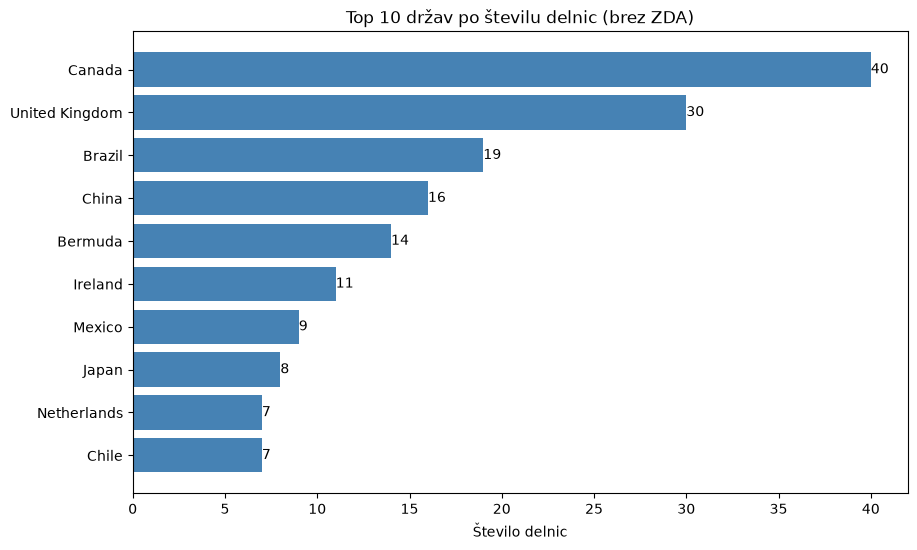

In [8]:
drzave_brez_zda = delnice[delnice["drzava"] != "USA"]["drzava"].value_counts().head(10)

plt.figure(figsize=(10, 6))
stolpci = plt.barh(drzave_brez_zda.index, drzave_brez_zda.values, color="steelblue")
plt.bar_label(stolpci)
plt.gca().invert_yaxis()
plt.title("Top 10 držav po številu delnic (brez ZDA)")
plt.xlabel("Število delnic")
plt.show()

Med delnicami močno prevladujejo ameriška podjetja: kar **761 od 1.000** (76,1 %) jih prihaja iz **ZDA**, iz ostalih držav  **239**.

Če ZDA izpustimo, največ delnic prihaja iz **Kanade** (40), **Združenega kraljestva** (30), **Brazilije** (19) in **Kitajske** (16). Skupaj je zastopanih 42 držav, vendar ima večina od njih le po nekaj podjetij.

Mogoče so podatki pristranski saj je  Finviz  ameriška platforma, ki se osredotoča predvsem na delnice, s katerimi se trguje na ameriških borzah.

## 5) Cena in dividendni donos

Ali imajo dražje delnice višji ali nižji dividendni donos kot cenejše?

In [9]:
top10_najdrazje = delnice.nlargest(10, "cena")[["podjetje", "sektor", "cena", "donos"]]
top10_najdrazje

,podjetje,sektor,cena,donos
680,Blackrock Inc,Financial,1078.33,2.11
710,Equinix Inc,Real Estate,1041.62,1.98
873,NewMarket Corp,Basic Materials,916.04,1.31
677,Goldman Sachs Group Inc,Financial,898.77,2.12
984,Deere & Co,Industrials,683.05,0.96
202,Dillard's Inc,Consumer Cyclical,669.04,4.89
830,MSCI Inc,Financial,558.24,1.47
793,Cummins Inc,Industrials,534.93,1.64
522,Lockheed Martin Corp,Industrials,507.99,2.76
850,Ameriprise Financial Inc,Financial,492.07,1.37


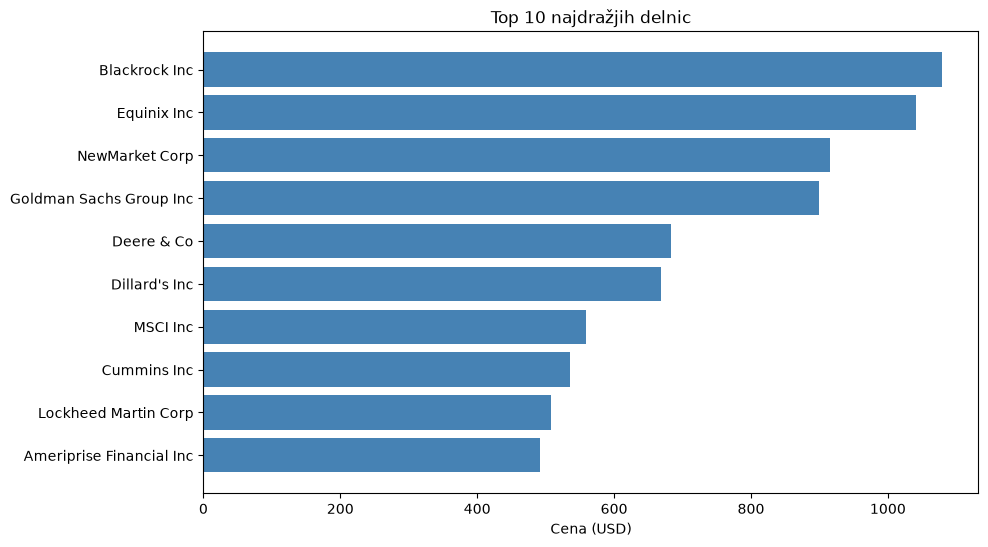

In [10]:
plt.figure(figsize=(10, 6))
plt.barh(top10_najdrazje["podjetje"], top10_najdrazje["cena"], color="steelblue")
plt.gca().invert_yaxis()
plt.title("Top 10 najdražjih delnic")
plt.xlabel("Cena (USD)")
plt.show()


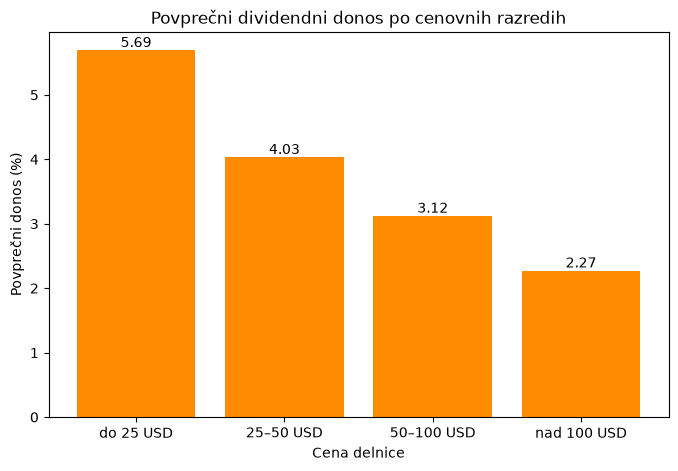

In [11]:
cenovni_razredi = pd.cut(
    delnice["cena"],
    bins=[0, 25, 50, 100, 10000],
    labels=["do 25 USD", "25–50 USD", "50–100 USD", "nad 100 USD"]
)
donos_po_ceni = delnice.groupby(cenovni_razredi)["donos"].mean().round(2)

plt.figure(figsize=(8, 5))
stolpci = plt.bar(donos_po_ceni.index.astype(str), donos_po_ceni.values, color="darkorange")
plt.bar_label(stolpci)
plt.title("Povprečni dividendni donos po cenovnih razredih")
plt.xlabel("Cena delnice")
plt.ylabel("Povprečni donos (%)")
plt.show()

Najdražja delnica je **Blackrock** (**1.078 USD**), sledita **Equinix** in **NewMarket**. Med najdražjimi prevladujejo velika ameriška finančna in industrijska podjetja. Opazimo, da imajo skoraj vse precej nizek donos, večinoma okoli **1–2 %**.

To potrjuje tudi primerjava po cenovnih razredih: z višanjem cene donos opazno pada. Delnice do **25 USD** imajo povprečni donos **5,69 %**, delnice nad **100 USD** pa le **2,27 %**. Razlog je v tem, da je donos izračunan kot dividenda deljeno s ceno: pri dragi delnici mora podjetje izplačati zelo visoko dividendo, da bi doseglo visok donos. 

## 6) Velikost podjetja in dividendni donos

Ali imajo večja podjetja višji ali nižji dividendni donos kot manjša?

In [12]:
top10_najvecja = delnice.nlargest(10, "trzna_kapitalizacija")[["podjetje", "sektor", "trzna_kapitalizacija", "donos"]]
top10_najvecja["trzna_kapitalizacija"] = (top10_najvecja["trzna_kapitalizacija"] / 1e9)
top10_najvecja = top10_najvecja.rename(columns={"trzna_kapitalizacija": "kapitalizacija (mrd USD)"})
top10_najvecja

,podjetje,sektor,kapitalizacija (mrd USD),donos
728,JPMorgan Chase & Co,Financial,881.45,1.93
990,Walmart Inc,Consumer Defensive,842.51,0.94
587,ExxonMobil Holdings Corp,Energy,677.29,2.52
681,Johnson & Johnson,Healthcare,609.42,2.11
571,Abbvie Inc,Healthcare,468.90,2.59
825,Cisco Systems Inc,Technology,452.96,1.49
855,Oracle Corp,Technology,438.96,1.36
391,Chevron Corp,Energy,409.24,3.45
655,Bank Of America Corp,Financial,377.71,2.21
588,Coca-Cola Co,Consumer Defensive,374.70,2.52


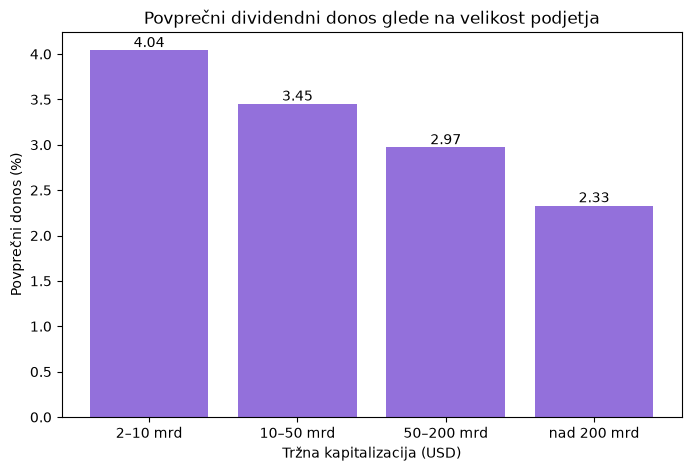

In [13]:
velikost = pd.cut(
    delnice["trzna_kapitalizacija"],
    bins=[0, 10e9, 50e9, 200e9, 10e12],
    labels=["2–10 mrd", "10–50 mrd", "50–200 mrd", "nad 200 mrd"]
)
donos_po_velikosti = delnice.groupby(velikost, observed=True)["donos"].mean().round(2)

plt.figure(figsize=(8, 5))
stolpci = plt.bar(donos_po_velikosti.index.astype(str), donos_po_velikosti.values, color="mediumpurple")
plt.bar_label(stolpci)
plt.title("Povprečni dividendni donos glede na velikost podjetja")
plt.xlabel("Tržna kapitalizacija (USD)")
plt.ylabel("Povprečni donos (%)")
plt.show()

Največje podjetje med izbranimi delnicami je **JPMorgan Chase** s tržno kapitalizacijo **881 milijard USD**, sledita **Walmart** (843 mrd) in **ExxonMobil** (677 mrd). Med največjimi so poznana podjetja iz različnih sektorjev, od bank do tehnologije in energetike. Njihov donos je večinoma nizek, med **1 in 3,5 %**, Walmart pa ima le **0,94 %**.

Primerjava po velikosti pokaže jasen vzorec: manjša podjetja imajo v povprečju višji donos. Podjetja, vredna **2–10 milijard USD**, imajo povprečni donos **4,04 %**, podjetja nad **200 milijard USD** pa le **2,33 %**. Velika podjetja so stabilnejša in zato manj tvegana, vlagatelji pa so zanje pripravljeni plačati višjo ceno, kar zniža donos. Dodatno je lahko visoka dividenda način da manjša podjetja privabijo nove investitorje.

## 7) Kako z 1.000.000 USD doseči čim višje dividende?

Recimo, da imamo za naložbo **1.000.000 USD** in bi radi prejemali čim višje dividende. Da se izognemo majhnim in tveganim podjetjem, upoštevamo le delnice s **tržno kapitalizacijo nad 5 milijard USD** in **dnevnim obsegom trgovanja nad 1 milijon delnic**. Med njimi izberemo **20 delnic z najvišjim donosom** in denar enakomerno razdelimo med njih.

In [14]:
# izberemo večja in aktivno trgovana podjetja
kandidati = delnice[
    (delnice["trzna_kapitalizacija"] > 5_000_000_000) &
    (delnice["obseg"] > 1_000_000)
]

# vzamemo 20 z najvišjim donosom
portfelj = kandidati.nlargest(20, "donos")

#  denar razdelimo enakomerno
kapital = 1_000_000 / len(portfelj)

#  koliko delnic kupimo in koliko dividend dobimo
portfelj["st_delnic"] = (kapital // portfelj["cena"]).astype(int)
portfelj["dividende"] = (portfelj["st_delnic"] * portfelj["dividenda"]).round(2)

skupaj = portfelj["dividende"].sum()
print(f"Letne dividende: {skupaj:,.2f} USD")
print(f"Donos portfelja: {skupaj / 1_000_000 * 100:.2f} %")

portfelj[["oznaka", "podjetje", "sektor", "drzava", "cena", "donos", "st_delnic", "dividende"]]

Letne dividende: 94,129.11 USD
Donos portfelja: 9.41 %


,oznaka,podjetje,sektor,drzava,cena,donos,st_delnic,dividende
4,PDI,PIMCO Dynamic Income Fund,Financial,USA,14.35,18.40,3484,9197.76
5,FRO,Frontline Plc,Energy,Cyprus,52.54,18.10,951,9044.01
7,AGNC,AGNC Investment Corp,Real Estate,USA,8.65,16.65,5780,8323.20
9,NLY,Annaly Capital Management Inc,Real Estate,USA,18.28,16.11,2735,8040.90
30,OWL,Blue Owl Capital Inc,Financial,USA,9.01,10.27,5549,5160.57
32,ARCC,Ares Capital Corp,Financial,USA,18.80,10.22,2659,5105.28
48,SBSW,Sibanye Stillwater Limited ADR,Basic Materials,South Africa,10.04,8.38,4980,4183.20
62,VICI,VICI Properties Inc,Real Estate,USA,22.83,7.98,2190,3985.80
64,GIS,General Mills Inc,Consumer Defensive,USA,32.22,7.62,1551,3815.46
69,PBR,Petroleo Brasileiro SA Petrobras ADR,Energy,Brazil,23.94,7.34,2088,3674.88


In [15]:
najvecja = delnice.nlargest(20, "trzna_kapitalizacija")
najvecja["st_delnic"] = (kapital // najvecja["cena"]).astype(int)
najvecja["dividende"] = najvecja["st_delnic"] * najvecja["dividenda"]

skupaj_najvecja = najvecja["dividende"].sum()
print(f"Letne dividende (20 največjih podjetij): {skupaj_najvecja:,.2f} USD")
print(f"Donos portfelja: {skupaj_najvecja / 1_000_000 * 100:.2f} %")

Letne dividende (20 največjih podjetij): 24,857.18 USD
Donos portfelja: 2.49 %


Pogoje izpolnjuje **150** delnic. Če med njimi izberemo 20 z najvišjim donosom in v vsako vložimo 50.000 USD, bi letno prejeli približno **94.100 USD** dividend, kar je **donos 9,41 %**. V portfelju prevladujejo **finance**, **nepremičnine** in **energetika**, po državah pa ZDA (12 delnic) in Brazilija (5 delnic).

Za primerjavo: če bi enak znesek razdelili med **20 največjih podjetij**, bi prejeli le okoli **24.900 USD** oziroma **2,49 %**. Portfelj z visokim donosom bi torej prinesel skoraj **štirikrat več** dividend.

Vendar je to bolj tvegano. Visok donos je pogosto posledica padca cene delnice ali negotovega poslovanja, zato ni nujno, da bodo podjetja takšne dividende izplačevala tudi v prihodnje.

## 8) Ugotovitve

Na podlagi analize 1.000 delnic z najvišjim dividendnim donosom sem prišel do naslednjih ugotovitev:

- **Večina delnic ima zmeren donos.** Mediana donosa je **2,88 %**, povprečje pa **3,62 %**. Največ delnic (393) ima donos med 2 in 4 %, donos nad 7 % pa ima le 80 delnic. Zelo visoki donosi so torej redki.

- **Sektor z največ delnicami ni sektor z najvišjim donosom.** Največ delnic je iz **finančnega sektorja** (261), najvišji povprečni donos pa imajo **nepremičnine** (5,13 %) in **energetika** (4,80 %). Najnižjega imajo **industrija**, **tehnologija** in **zdravstvo** (okoli 2,5 %).

- **Prevladujejo ameriška podjetja.** Kar **76 %** delnic je iz ZDA, sledijo Kanada, Združeno kraljestvo in Brazilija.

- **Dražje delnice imajo nižji donos.** Delnice do 25 USD imajo povprečni donos **5,69 %**, delnice nad 100 USD pa le **2,27 %**.

- **Večja podjetja imajo nižji donos.** Podjetja, vredna 2–10 milijard USD, imajo povprečni donos **4,04 %**, podjetja nad 200 milijard USD pa **2,33 %**. Velika in stabilna podjetja so za vlagatelje manj tvegana, zato je njihov donos nižji.

- **Visok donos prinese več, a z večjim tveganjem.** Portfelj 20 delnic z najvišjim donosom bi z naložbo 1.000.000 USD prinesel okoli **94.100 USD** dividend na leto (**9,41 %**), portfelj 20 največjih podjetij pa le okoli **24.900 USD** (**2,49 %**). Pri izbiri delnic zgolj po donosu je treba upoštevati, da so visoke dividende pogosto znak večjega tveganja.